In [9]:
!pip -q install nltk wordcloud pyLDAvis

Download and load dataset

In [10]:
import requests
import pandas as pd
from io import BytesIO

repo_api = "https://api.github.com/repos/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/contents"

response = requests.get(repo_api)
response.raise_for_status()

files = response.json()

candidates = [
    f for f in files
    if f["type"] == "file"
    and f["name"].lower().endswith((".csv", ".csv.gz", ".json", ".jsonl", ".gz"))
]

print("Available dataset files:")
for f in candidates:
    print(f["name"], f["download_url"])

if not candidates:
    raise FileNotFoundError("No dataset files found in the repository.")

# Prefer a CSV file when available
file_info = next(
    (f for f in candidates if f["name"].lower().endswith(".csv")),
    candidates[0]
)

download = requests.get(file_info["download_url"])
download.raise_for_status()

filename = file_info["name"].lower()

if filename.endswith(".csv.gz") or filename.endswith(".gz"):
    df = pd.read_csv(BytesIO(download.content), compression="gzip")
elif filename.endswith(".csv"):
    df = pd.read_csv(BytesIO(download.content))
elif filename.endswith(".jsonl"):
    df = pd.read_json(BytesIO(download.content), lines=True)
else:
    try:
        df = pd.read_json(BytesIO(download.content))
    except ValueError:
        df = pd.read_json(BytesIO(download.content), lines=True)

print("\nDownloaded:", file_info["name"])
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Available dataset files:
Adult_Immunization_Features_Headlines.csv https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Adult_Immunization_Features_Headlines.csv
Adult_Immunization_Features_Headlines.gz https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Adult_Immunization_Features_Headlines.gz
Adult_Immunization_News_Headlines.csv https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Adult_Immunization_News_Headlines.csv
Adult_Immunization_News_Headlines.gz https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Adult_Immunization_News_Headlines.gz
Adverse_Drug_Events_Related_Headlines.csv https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Adverse

,Date,Source,Headlines,Teaser
0,October 2004,Medscape Infectious Diseases,"Infectious Diseases: October 30, 2004","Dr. Bartlett reviews the latest on influenza, ..."
1,July 2004,Journal of the American Board of Family Medicine,Influenza Vaccination in Pregnancy,Are enough family physicians and obstetricians...
2,June 2004,Medscape Nurses,Bacterial Meningitis: A Deadly But Preventable...,Those whose lives have been touched by this le...
3,April 2004,Alimentary Pharmacology & Therapeutics,Hepatitis Vaccination in Patients With Chronic...,Despite a declining incidence of acute viral h...
4,November 2003,Medscape Infectious Diseases,Emerging Infections,Dr. John Bartlett reports on the latest data f...


Select the text columns

In [11]:
text_cols = [
    col for col in df.columns
    if any(word in col.lower() for word in
           ["headline", "title", "teaser", "description", "text", "content"])
]

if not text_cols:
    raise ValueError(f"No text columns found. Available columns: {df.columns.tolist()}")

print("Selected text columns:", text_cols)

df["text"] = df[text_cols].fillna("").astype(str).agg(" ".join, axis=1)
df = df[df["text"].str.strip().ne("")].copy()
df = df.reset_index(drop=True)

print("Total text records:", len(df))
display(df[["text"]].head())

Selected text columns: ['Headlines', 'Teaser']
Total text records: 366


,text
0,"Infectious Diseases: October 30, 2004 Dr. Bart..."
1,Influenza Vaccination in Pregnancy Are enough ...
2,Bacterial Meningitis: A Deadly But Preventable...
3,Hepatitis Vaccination in Patients With Chronic...
4,Emerging Infections Dr. John Bartlett reports ...


#Preprocess and clean the text

In [12]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    tokens = word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return tokens

df["tokens"] = df["text"].apply(preprocess_text)
df["cleaned_text"] = df["tokens"].apply(lambda x: " ".join(x))

print("Original and cleaned text samples:")
display(df[["text", "cleaned_text"]].head(5))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Original and cleaned text samples:


,text,cleaned_text
0,"Infectious Diseases: October 30, 2004 Dr. Bart...",infectious disease october bartlett review lat...
1,Influenza Vaccination in Pregnancy Are enough ...,influenza vaccination pregnancy enough family ...
2,Bacterial Meningitis: A Deadly But Preventable...,bacterial meningitis deadly preventable diseas...
3,Hepatitis Vaccination in Patients With Chronic...,hepatitis vaccination patient chronic liver di...
4,Emerging Infections Dr. John Bartlett reports ...,emerging infection john bartlett report latest...


#Word frequency distribution and word cloud

Top 20 frequent words:
[('vaccine', 253), ('influenza', 160), ('flu', 102), ('vaccination', 91), ('new', 87), ('patient', 80), ('disease', 64), ('adult', 62), ('recommendation', 55), ('hpv', 52), ('cdc', 42), ('immunization', 41), ('study', 38), ('year', 36), ('review', 34), ('need', 32), ('health', 32), ('infection', 31), ('cancer', 31), ('latest', 29)]


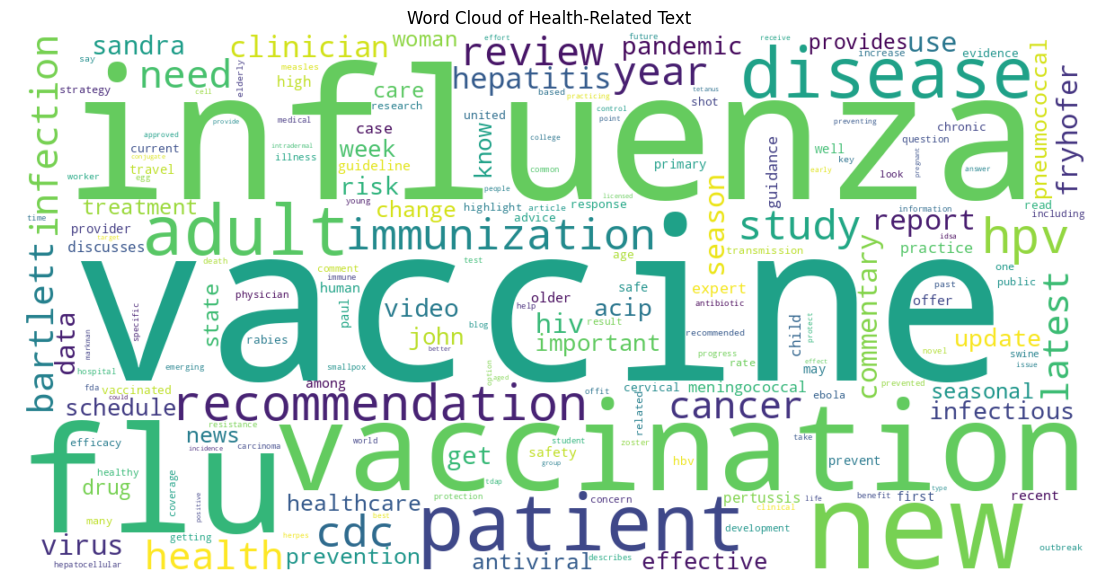

In [13]:
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

all_words = [
    word
    for tokens in df["tokens"]
    for word in tokens
]

word_freq = Counter(all_words)

print("Top 20 frequent words:")
print(word_freq.most_common(20))

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white"
).generate_from_frequencies(word_freq)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Health-Related Text")
plt.show()

# Plot the top 20 frequent words

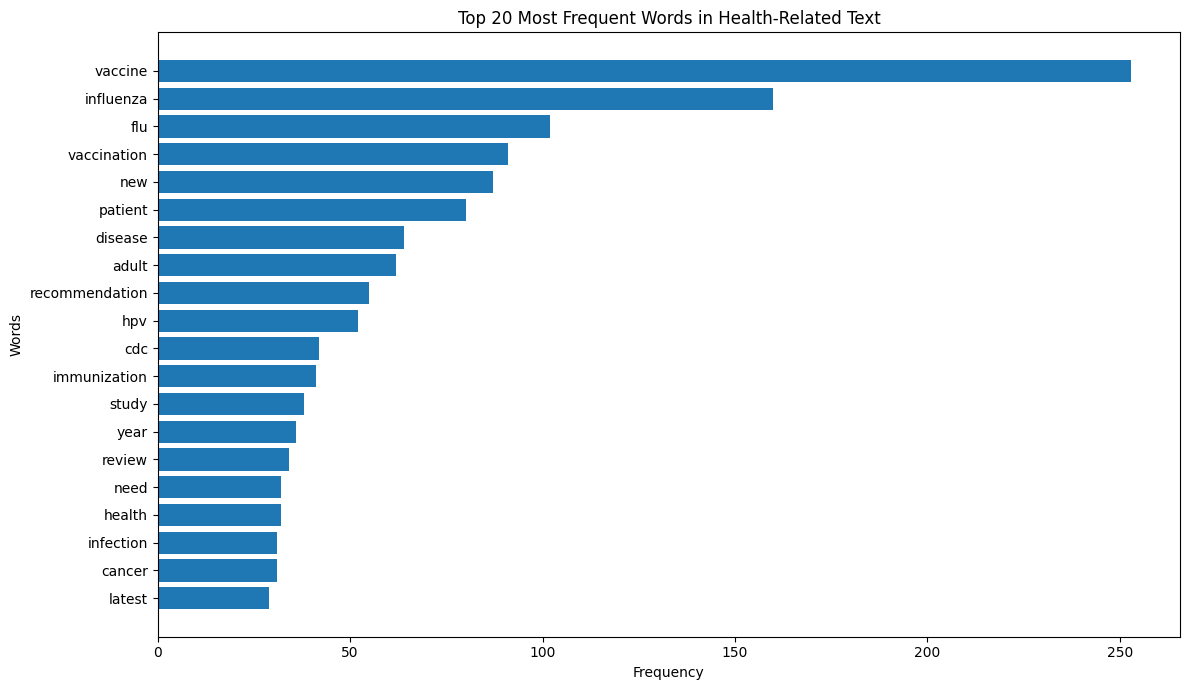

In [14]:
top_20 = word_freq.most_common(20)

words = [item[0] for item in top_20]
frequencies = [item[1] for item in top_20]

plt.figure(figsize=(12, 7))
plt.barh(words[::-1], frequencies[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words in Health-Related Text")
plt.tight_layout()
plt.show()

#Topic modelling using LDA

In [15]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

vectorizer = CountVectorizer(
    max_features=5000,
    min_df=2,
    max_df=0.95
)

dtm = vectorizer.fit_transform(df["cleaned_text"])

lda_model = LatentDirichletAllocation(
    n_components=5,
    max_iter=10,
    random_state=42,
    learning_method="batch"
)

lda_model.fit(dtm)

feature_names = vectorizer.get_feature_names_out()

print("Top 5 words for each topic:\n")

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-5:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")

Top 5 words for each topic:

Topic 1: adult, immunization, vaccine, fryhofer, vaccination
Topic 2: vaccine, flu, cdc, patient, commentary
Topic 3: disease, patient, hepatitis, infection, virus
Topic 4: vaccine, influenza, hpv, new, cancer
Topic 5: influenza, flu, vaccination, health, pandemic


#Visualize topics using pyLDAvis

In [17]:
import pyLDAvis
import pyLDAvis.lda_model

vis = pyLDAvis.lda_model.prepare(
    lda_model,
    dtm,
    vectorizer,
    mds="pcoa"
)

pyLDAvis.display(vis)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#Display the dominant topic for each text sample

In [18]:
topic_distribution = lda_model.transform(dtm)

df["dominant_topic"] = topic_distribution.argmax(axis=1) + 1

print("Sample texts with their dominant topics:")
display(df[["text", "cleaned_text", "dominant_topic"]].head(10))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Sample texts with their dominant topics:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,text,cleaned_text,dominant_topic
0,"Infectious Diseases: October 30, 2004 Dr. Bart...",infectious disease october bartlett review lat...,3
1,Influenza Vaccination in Pregnancy Are enough ...,influenza vaccination pregnancy enough family ...,5
2,Bacterial Meningitis: A Deadly But Preventable...,bacterial meningitis deadly preventable diseas...,3
3,Hepatitis Vaccination in Patients With Chronic...,hepatitis vaccination patient chronic liver di...,3
4,Emerging Infections Dr. John Bartlett reports ...,emerging infection john bartlett report latest...,1
5,"New Organisms, New Drugs, New Tests, New Guide...",new organism new drug new test new guideline r...,1
6,Asthma and Influenza Vaccination The public he...,asthma influenza vaccination public health bur...,5
7,Some Answers to Smallpox Vaccination Questions...,answer smallpox vaccination question progress ...,3
8,Flu Vaccine for Cardiovascular Prevention in t...,flu vaccine cardiovascular prevention elderly ...,2
9,October 2002 Read about the new drug approval ...,october read new drug approval hepsera chronic...,2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag